# Lista de Exercícios 3 — Caminhos Mínimos: Dijkstra, Bellman-Ford e Floyd-Warshall

**Instituição:** Instituto Federal Goiano — Campus Iporá (Bacharelado em Ciência da Computação)  
**Disciplina:** Teoria dos Grafos • 3º Período — 2026/2  
**Professor:** Prof. Newarney T. Costa  
**Integrantes:** Messias Junio da Silva Mendes (`Messias-Mendes-Oficial`) | Bruno Alves Mendonça De Abreu Filho  

Este notebook foi estruturado para rodar integralmente no **Google Colab** (com códigos em **Python 3** e compilação em **C via `gcc`**) cobrindo todas as questões teóricas, testes de mesa passo a passo e implementações da **Lista de Exercícios 3**.

## Questão 1 — Algoritmo de Dijkstra (Um-para-Todos)

**Grafo não orientado com pesos — vértices $a, b, c, d, e, f$ (mapeados para $0, 1, 2, 3, 4, 5$):**  
$$a\text{--}b(4),\; a\text{--}c(2),\; b\text{--}c(1),\; b\text{--}d(5),\; c\text{--}d(8),\; c\text{--}e(10),\; d\text{--}e(2),\; d\text{--}f(6),\; e\text{--}f(3)$$

### 1.1 Como o Dijkstra funciona, principais características e limitações (pesos negativos)
* **Funcionamento:** O algoritmo de Dijkstra resolve o problema do caminho mínimo de **fonte única** (*um-para-todos*) mantendo uma estimativa de distância `dist[v]` para cada vértice (inicializada com $0$ na origem e $\infty$ nos demais) e dividindo os vértices em dois conjuntos: **abertos** (ainda não fechados) e **fechados** (cuja distância mínima já é definitiva). A cada passo, seguindo uma **estratégia gulosa**, ele seleciona o vértice aberto `u` com a **menor distância provisória**, marca `u` como fechado (`*`) e **relaxa** todas as arestas incidentes `(u, v)` para vizinhos abertos `v`: se `dist[u] + peso(u, v) < dist[v]`, atualiza `dist[v] = dist[u] + peso(u, v)` e define `antecessor[v] = u`.
* **Principais Características:**
  * Estratégia **gulosa** (*greedy*): nunca reabre um vértice após fechá-lo.
  * Complexidade de tempo: **$O(V^2)$** com busca linear em vetor/matriz de adjacência (como no código da lista), ou **$O((V + E) \log V)$** usando lista de adjacência e Fila de Prioridade (Min-Heap).
* **Limitações (O que acontece com arestas de peso negativo?):**
  * O Dijkstra **NÃO funciona corretamente com arestas de peso negativo** (mesmo que não haja ciclos negativos).
  * **Por quê?** A prova de corretude do Dijkstra baseia-se na premissa de que, ao escolher o vértice aberto `u` de menor `dist[u]`, nenhum caminho alternativo passando por outros vértices abertos `w` (que têm `dist[w] >= dist[u]`) poderá chegar a `u` com custo menor, pois adicionar novas arestas de peso $\ge 0$ nunca diminui o custo acumulado. Se houver uma aresta de peso negativo mais adiante, um caminho mais longo em número de arestas pode ter custo total menor e melhorar a distância de um vértice que o Dijkstra já fechou definitivamente, levando a resultados incorretos.

### 1.2 Aplicação Manual do Dijkstra (Tabela Iteração por Iteração)

| Vértice | Inicial | Iter. 1 (Fecha **a**) | Iter. 2 (Fecha **c**) | Iter. 3 (Fecha **b**) | Iter. 4 (Fecha **d**) | Iter. 5 (Fecha **e**) | Iter. 6 (Fecha **f**) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **a (0)** | `0 \| [ ] \| -` | **`0 \| [*] \| -`** | `0 \| [*] \| -` | `0 \| [*] \| -` | `0 \| [*] \| -` | `0 \| [*] \| -` | `0 \| [*] \| -` |
| **b (1)** | `∞ \| [ ] \| -` | `4 \| [ ] \| a` | `3 \| [ ] \| c` | **`3 \| [*] \| c`** | `3 \| [*] \| c` | `3 \| [*] \| c` | `3 \| [*] \| c` |
| **c (2)** | `∞ \| [ ] \| -` | `2 \| [ ] \| a` | **`2 \| [*] \| a`** | `2 \| [*] \| a` | `2 \| [*] \| a` | `2 \| [*] \| a` | `2 \| [*] \| a` |
| **d (3)** | `∞ \| [ ] \| -` | `∞ \| [ ] \| -` | `10 \| [ ] \| c` | `8 \| [ ] \| b` | **`8 \| [*] \| b`** | `8 \| [*] \| b` | `8 \| [*] \| b` |
| **e (4)** | `∞ \| [ ] \| -` | `∞ \| [ ] \| -` | `12 \| [ ] \| c` | `12 \| [ ] \| c` | `10 \| [ ] \| d` | **`10 \| [*] \| d`** | `10 \| [*] \| d` |
| **f (5)** | `∞ \| [ ] \| -` | `∞ \| [ ] \| -` | `∞ \| [ ] \| -` | `∞ \| [ ] \| -` | `14 \| [ ] \| d` | `13 \| [ ] \| e` | **`13 \| [*] \| e`** |

*(Notação em cada célula: `Distância | Fechado (*) | Antecessor`)*

* **Recuperação do caminho mínimo de $a$ até $f$ pelos antecessores:**
  * $\text{ant}[f] = e \implies \text{ant}[e] = d \implies \text{ant}[d] = b \implies \text{ant}[b] = c \implies \text{ant}[c] = a$.
  * **Caminho mínimo:** $\mathbf{a \xrightarrow{2} c \xrightarrow{1} b \xrightarrow{5} d \xrightarrow{2} e \xrightarrow{3} f}$ — **Distância mínima total = $13$**.

Distancia de 0 (a) ate 0 (a) = 0
Distancia de 0 (a) ate 1 (b) = 3
Distancia de 0 (a) ate 2 (c) = 2
Distancia de 0 (a) ate 3 (d) = 8
Distancia de 0 (a) ate 4 (e) = 10
Distancia de 0 (a) ate 5 (f) = 13

Caminho minimo de a ate f: a -> c -> b -> d -> e -> f (Custo = 13)


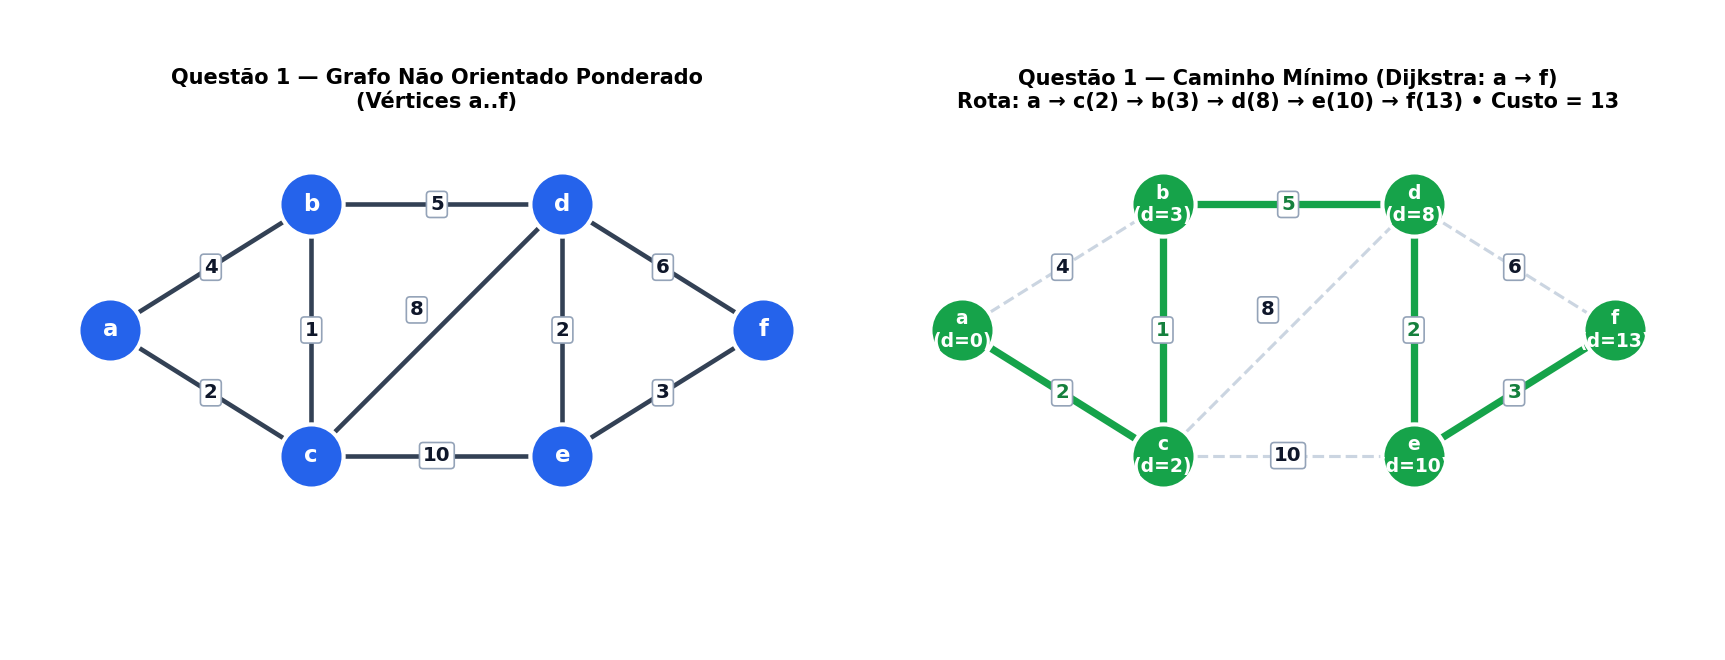

In [1]:
# Questão 1.3 — Implementação Completa do Dijkstra em Python (Google Colab)
import sys
V = 6

def distancia_minima(dist, visitado):
    min_val, min_index = sys.maxsize, -1
    for v in range(V):
        if not visitado[v] and dist[v] <= min_val:
            min_val, min_index = dist[v], v
    return min_index

def dijkstra(grafo, origem):
    nomes = ['a', 'b', 'c', 'd', 'e', 'f']
    dist = [sys.maxsize] * V
    visitado = [False] * V
    antecessor = [-1] * V
    dist[origem] = 0

    for _ in range(V - 1):
        u = distancia_minima(dist, visitado)
        visitado[u] = True
        for v in range(V):
            # Condição de relaxamento:
            if not visitado[v] and grafo[u][v] > 0 and dist[u] != sys.maxsize and dist[u] + grafo[u][v] < dist[v]:
                dist[v] = dist[u] + grafo[u][v]
                antecessor[v] = u

    for i in range(V):
        print(f"Distancia de {origem} ({nomes[origem]}) ate {i} ({nomes[i]}) = {dist[i]}")

    # Reconstruindo o caminho de a (0) até f (5)
    caminho = []
    atual = 5
    while atual != -1:
        caminho.append(nomes[atual])
        atual = antecessor[atual]
    caminho.reverse()
    print(f"\nCaminho minimo de a ate f: {' -> '.join(caminho)} (Custo = {dist[5]})")

# Matriz de adjacência simétrica (grafo não orientado: a=0, b=1, c=2, d=3, e=4, f=5)
grafo = [
    [0, 4, 2, 0,  0, 0], # a (0)
    [4, 0, 1, 5,  0, 0], # b (1)
    [2, 1, 0, 8, 10, 0], # c (2)
    [0, 5, 8, 0,  2, 6], # d (3)
    [0, 0, 10, 2, 0, 3], # e (4)
    [0, 0, 0, 6,  3, 0]  # f (5)
]
dijkstra(grafo, 0)

In [2]:
# Questão 1.3 — Implementação Completa do Dijkstra em C (Compilada com gcc no Colab)
dijkstra_c = r'''#include <stdio.h>
#include <limits.h>
#define V 6

int distanciaMinima(int dist[], int visitado[]) {
    int min = INT_MAX, min_index = -1;
    for (int v = 0; v < V; v++)
        if (!visitado[v] && dist[v] <= min) { min = dist[v]; min_index = v; }
    return min_index;
}

void dijkstra(int grafo[V][V], int origem) {
    int dist[V], visitado[V];
    for (int i = 0; i < V; i++) { dist[i] = INT_MAX; visitado[i] = 0; }
    dist[origem] = 0;
    for (int count = 0; count < V - 1; count++) {
        int u = distanciaMinima(dist, visitado);
        visitado[u] = 1;
        for (int v = 0; v < V; v++) {
            // Condicao de relaxamento
            if (!visitado[v] && grafo[u][v] && dist[u] != INT_MAX && dist[u] + grafo[u][v] < dist[v]) {
                dist[v] = dist[u] + grafo[u][v];
            }
        }
    }
    for (int i = 0; i < V; i++)
        printf("Distancia de %d ate %d = %d\n", origem, i, dist[i]);
}

int main() {
    int grafo[V][V] = {
        {0, 4, 2, 0,  0, 0},
        {4, 0, 1, 5,  0, 0},
        {2, 1, 0, 8, 10, 0},
        {0, 5, 8, 0,  2, 6},
        {0, 0, 10, 2, 0, 3},
        {0, 0, 0, 6,  3, 0}
    };
    dijkstra(grafo, 0);
    return 0;
}
'''
with open("dijkstra.c", "w") as f:
    f.write(dijkstra_c)
import subprocess
subprocess.run(["gcc", "dijkstra.c", "-o", "dijkstra"], check=True)
print(subprocess.run(["./dijkstra"], capture_output=True, text=True, check=True).stdout, end="")

Distancia de 0 ate 0 = 0
Distancia de 0 ate 1 = 3
Distancia de 0 ate 2 = 2
Distancia de 0 ate 3 = 8
Distancia de 0 ate 4 = 10
Distancia de 0 ate 5 = 13


## Questão 2 — Algoritmo de Bellman-Ford (Pesos Negativos)

**Grafo orientado com pesos — vértices $A, B, C, D, E, F$ (mapeados para $0..5$, com $V = 6, E = 9$):**  
$$A\to B(4),\; A\to C(2),\; B\to C(-1),\; B\to D(2),\; C\to D(3),\; C\to E(2),\; D\to F(2),\; E\to D(-3),\; E\to F(3)$$

### 2.1 Como o Bellman-Ford lida com pesos negativos, detecção de ciclo negativo e diferença para o Dijkstra
* **Como lida com pesos negativos:** Em vez de fechar vértices de maneira gulosa e irreversível, o Bellman-Ford aplica o método de **Programação Dinâmica** relaxando **todas as $E$ arestas do grafo em $V - 1$ rodadas sucessivas**. Como qualquer caminho mínimo simples em um grafo de $V$ vértices contém no máximo $V - 1$ arestas, após $k$ rodadas o algoritmo garante ter encontrado os caminhos mínimos que usam até $k$ arestas — permitindo que reduções provocadas por arcos negativos (como $E \to D(-3)$) se propaguem para os demais vértices nas rodadas seguintes.
* **Condição que identifica um ciclo de peso negativo:** Após concluir as $V - 1$ iterações (quando todas as distâncias mínimas já deveriam ter estabilizado), executa-se uma **$V$-ésima varredura sobre todas as arestas $(u, v)$**. Se ainda existir alguma aresta tal que:
  $$\text{dist}[u] \neq \infty \quad \text{e} \quad \text{dist}[u] + \text{peso}(u, v) < \text{dist}[v]$$
  então o custo continua diminuindo indefinidamente após $V - 1$ passos, o que prova a existência de um **ciclo de peso negativo** alcançável a partir da origem.
* **Diferença principal para o Dijkstra:** O **Dijkstra** é **guloso** (fecha 1 vértice por passo e nunca o reavalia, custando $O(V^2)$ ou $O((V+E)\log V)$, mas exigindo pesos $\ge 0$), enquanto o **Bellman-Ford** realiza **relaxamento global iterativo** ($V-1$ passagens por todas as $E$ arestas, custando **$O(V \cdot E)$**, porém suportando pesos negativos e detectando ciclos negativos).

### 2.2 Aplicação Manual do Bellman-Ford a partir de $A$

Avaliando as 9 arestas na ordem exata da lista: `(A→B:4), (A→C:2), (B→C:-1), (B→D:2), (C→D:3), (C→E:2), (D→F:2), (E→D:-3), (E→F:3)`:

| Vértice | Inicial | Após Iteração 1 | Após Iteração 2 | Após Iterações 3, 4 e 5 | Verificação (6ª passagem) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **A (0)** | `0 \| -` | `0 \| -` | `0 \| -` | `0 \| -` | Sem alteração |
| **B (1)** | `∞ \| -` | `4 \| A` | `4 \| A` | `4 \| A` | Sem alteração |
| **C (2)** | `∞ \| -` | `2 \| A` *(pois 4-1=3 > 2)* | `2 \| A` | `2 \| A` | Sem alteração |
| **D (3)** | `∞ \| -` | `1 \| E` *(B→D:6, C→D:5, E→D:4-3=1)* | `1 \| E` | `1 \| E` | Sem alteração |
| **E (4)** | `∞ \| -` | `4 \| C` *(C→E: 2+2=4)* | `4 \| C` | `4 \| C` | Sem alteração |
| **F (5)** | `∞ \| -` | `7 \| D` *(D→F avaliado quando D valia 5)* | **`3 \| D`** *(D→F com D=1: 1+2=3)* | `3 \| D` | Sem alteração |

* **Existe ciclo de peso negativo?** **Não.** Na verificação após a 5ª iteração, nenhuma aresta satisfaz `dist[u] + peso < dist[v]`.
* **Caminho mínimo de $A$ até $F$:** $A \xrightarrow{2} C \xrightarrow{2} E \xrightarrow{-3} D \xrightarrow{2} F$ (Custo total = **$3$**).

Iteracao 1: dist = [0, 4, 2, 1, 4, 7]
Iteracao 2: dist = [0, 4, 2, 1, 4, 3]
Iteracao 3: dist = [0, 4, 2, 1, 4, 3]
Iteracao 4: dist = [0, 4, 2, 1, 4, 3]
Iteracao 5: dist = [0, 4, 2, 1, 4, 3]

Nenhum ciclo de peso negativo detectado.
Distancia de A (0) ate A (0) =  0 | Antecessor: -
Distancia de A (0) ate B (1) =  4 | Antecessor: A
Distancia de A (0) ate C (2) =  2 | Antecessor: A
Distancia de A (0) ate D (3) =  1 | Antecessor: E
Distancia de A (0) ate E (4) =  4 | Antecessor: C
Distancia de A (0) ate F (5) =  3 | Antecessor: D


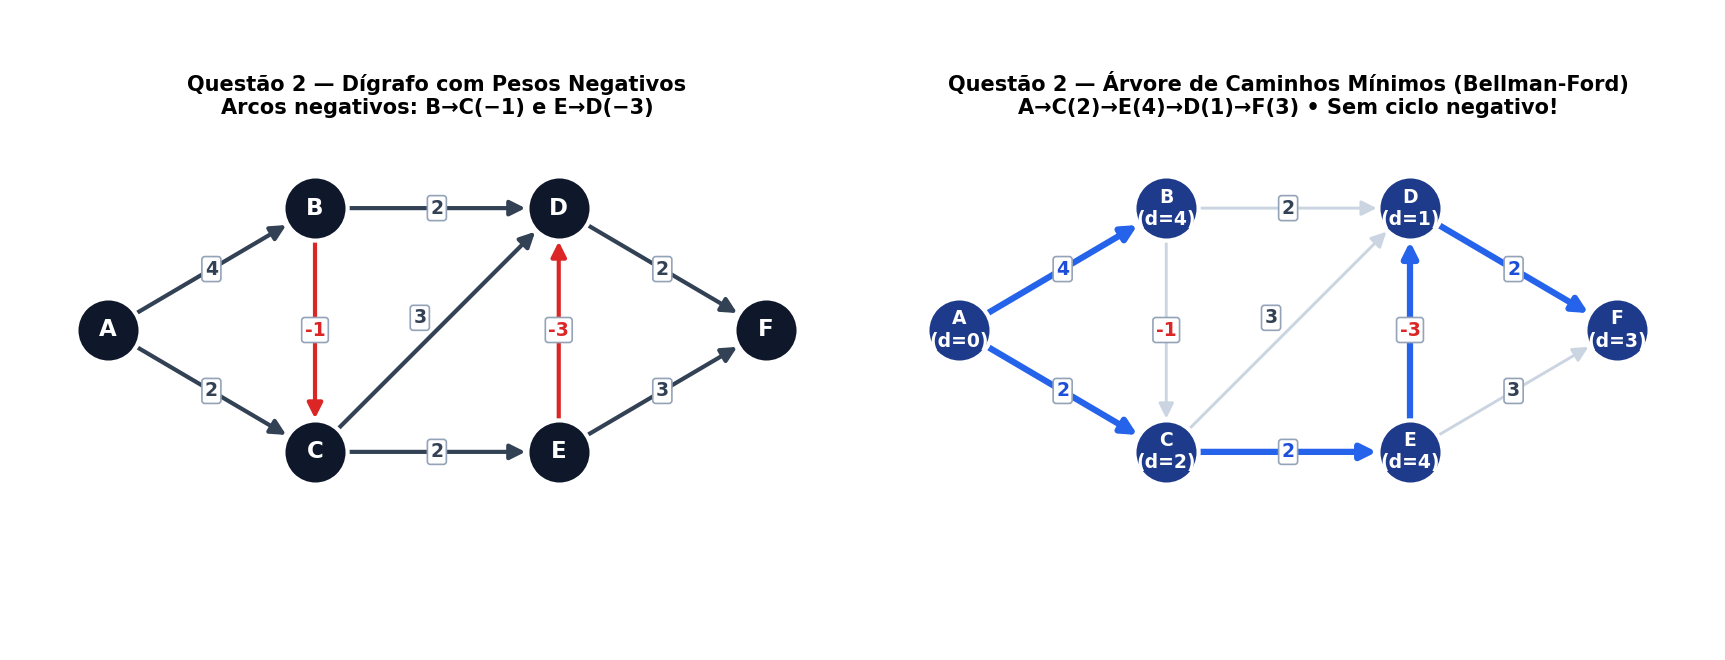

In [3]:
# Questão 2.3 — Implementação Completa do Bellman-Ford em Python (Google Colab)
V, E = 6, 9

def bellman_ford(arestas, origem):
    nomes = ['A', 'B', 'C', 'D', 'E', 'F']
    dist = [float('inf')] * V
    ant = [-1] * V
    dist[origem] = 0

    # V - 1 iterações de relaxamento das arestas
    for k in range(1, V):
        alterou = False
        for u, v, peso in arestas:
            if dist[u] != float('inf') and dist[u] + peso < dist[v]:
                dist[v] = dist[u] + peso
                ant[v] = u
                alterou = True
        print(f"Iteracao {k}: dist = {dist}")

    # Verificar presença de ciclo de peso negativo
    ciclo_negativo = False
    for u, v, peso in arestas:
        if dist[u] != float('inf') and dist[u] + peso < dist[v]:
            ciclo_negativo = True
            break

    if ciclo_negativo:
        print("\nGrafo contem ciclo de peso negativo!")
    else:
        print("\nNenhum ciclo de peso negativo detectado.")
        for i in range(V):
            pred = nomes[ant[i]] if ant[i] != -1 else "-"
            print(f"Distancia de {nomes[origem]} ({origem}) ate {nomes[i]} ({i}) = {dist[i]:2d} | Antecessor: {pred}")

arestas = [
    (0,1,4), (0,2,2), (1,2,-1), (1,3,2),
    (2,3,3), (2,4,2), (3,5,2), (4,3,-3), (4,5,3)
]
bellman_ford(arestas, 0)

In [4]:
# Questão 2.3 — Implementação Completa do Bellman-Ford em C (Compilada com gcc no Colab)
bellman_c = r'''#include <stdio.h>
#include <limits.h>
#define V 6
#define E 9

struct Edge { int origem, destino, peso; };

void bellmanFord(struct Edge arestas[], int origem) {
    int dist[V];
    for (int i = 0; i < V; i++) dist[i] = INT_MAX;
    dist[origem] = 0;

    // V-1 iteracoes de relaxamento das arestas
    for (int i = 1; i <= V - 1; i++) {
        for (int j = 0; j < E; j++) {
            int u = arestas[j].origem;
            int v = arestas[j].destino;
            int peso = arestas[j].peso;
            if (dist[u] != INT_MAX && dist[u] + peso < dist[v]) {
                dist[v] = dist[u] + peso;
            }
        }
    }

    // Verificar presenca de ciclo de peso negativo
    for (int j = 0; j < E; j++) {
        int u = arestas[j].origem;
        int v = arestas[j].destino;
        int peso = arestas[j].peso;
        if (dist[u] != INT_MAX && dist[u] + peso < dist[v]) {
            printf("Grafo contem ciclo de peso negativo!\n");
            return;
        }
    }

    printf("Nenhum ciclo de peso negativo encontrado.\n");
    for (int i = 0; i < V; i++)
        printf("Distancia de %d ate %d = %d\n", origem, i, dist[i]);
}

int main() {
    struct Edge arestas[E] = {
        {0,1,4}, {0,2,2}, {1,2,-1}, {1,3,2},
        {2,3,3}, {2,4,2}, {3,5,2}, {4,3,-3}, {4,5,3}
    };
    bellmanFord(arestas, 0);
    return 0;
}
'''
with open("bellman_ford.c", "w") as f:
    f.write(bellman_c)
import subprocess
subprocess.run(["gcc", "bellman_ford.c", "-o", "bellman_ford"], check=True)
print(subprocess.run(["./bellman_ford"], capture_output=True, text=True, check=True).stdout, end="")

Nenhum ciclo de peso negativo encontrado.
Distancia de 0 ate 0 = 0
Distancia de 0 ate 1 = 4
Distancia de 0 ate 2 = 2
Distancia de 0 ate 3 = 1
Distancia de 0 ate 4 = 4
Distancia de 0 ate 5 = 3


## Questão 3 — Algoritmo de Floyd-Warshall (Todos os Pares)

**Grafo orientado com pesos — vértices $A, B, C, D, E, F$ ($0..5$):**  
$$A\to B(4),\; A\to C(2),\; B\to C(3),\; B\to D(2),\; C\to D(4),\; C\to E(5),\; D\to E(1),\; E\to F(2),\; D\to F(6)$$

### 3.1 Explicação do Floyd-Warshall (Estruturas, Atualização por $k$ e Complexidade)
* **Estruturas de dados:**
  1. **Matriz de Distâncias $D$ (`dist[V][V]`):** Inicializada com $D_{ii} = 0$, $D_{ij} = \text{peso}(i, j)$ se existir o arco $i \to j$, ou $\infty$ caso contrário. Ao final, `dist[i][j]` armazena a distância mínima entre todo par de vértices $(i, j)$.
  2. **Matriz de Roteamento / Sucessores $R$ (`prox[V][V]` ou `ant[V][V]`):** Registra o próximo vértice no caminho mínimo de $i$ até $j$ (inicializada com $R_{ij} = j$ onde há arco direto) ou o último vértice intermediário $k$ que melhorou o caminho, permitindo reconstruir a sequência exata de vértices do caminho mínimo entre quaisquer dois nós.
* **Como a matriz é atualizada a cada vértice intermediário $k$:**
  Para cada vértice $k \in \{0, 1, \dots, V-1\}$, testamos para todos os pares $(i, j)$ se passar por $k$ como intermediário ($i \leadsto k \leadsto j$) é mais curto do que o melhor caminho atual de $i$ até $j$:
  $$\text{Se } \text{dist}[i][k] + \text{dist}[k][j] < \text{dist}[i][j] \implies \begin{cases} \text{dist}[i][j] = \text{dist}[i][k] + \text{dist}[k][j] \\ \text{prox}[i][j] = \text{prox}[i][k] \end{cases}$$
* **Complexidade de tempo:** Possui três laços `for` aninhados (`k`, `i`, `j`) de tamanho $V$, realizando $V \times V \times V = V^3$ operações constantes $\implies$ **$\Theta(V^3)$** em tempo e **$\Theta(V^2)$** em memória.

### 3.2 Aplicação Manual Passo a Passo (Evolução de $D^{(k)}$ e Caminho de $A$ até $F$)
* **Matriz Inicial $D^{(0)}$ e após $k = 0 (A)$:** Como nenhum arco entra em $A$, $D^{(A)} = D^{(0)}$.
* **Após $k = 1 (B)$:** A partir de $A \to B(4)$, descobre-se $A \to B \to D = 4 + 2 = \mathbf{6}$ (Logo `dist[A][D] = 6`, `prox[A][D] = B`).
* **Após $k = 2 (C)$:**
  * $A \to C \to D = 2 + 4 = 6$ (empata com `dist[A][D] = 6`);
  * $A \to C \to E = 2 + 5 = \mathbf{7}$ (`dist[A][E] = 7`, `prox[A][E] = C`);
  * $B \to C \to E = 3 + 5 = \mathbf{8}$ (`dist[B][E] = 8`).
* **Após $k = 3 (D)$:**
  * $A \to \dots \to D \to E = 6 + 1 = 7$ (empata com `dist[A][E] = 7`);
  * $A \to \dots \to D \to F = 6 + 6 = \mathbf{12}$ (`dist[A][F] = 12`);
  * $B \to D \to E = 2 + 1 = \mathbf{3}$ (`dist[B][E] = 3`);
  * $B \to D \to F = 2 + 6 = \mathbf{8}$ (`dist[B][F] = 8`);
  * $C \to D \to E = 4 + 1 = 5$ (empata com `dist[C][E] = 5`);
  * $C \to D \to F = 4 + 6 = \mathbf{10}$ (`dist[C][F] = 10`).
* **Após $k = 4 (E)$:**
  * $A \to \dots \to E \to F = 7 + 2 = \mathbf{9} < 12 \implies$ **`dist[A][F] = 9`**!
  * $B \to D \to E \to F = 3 + 2 = \mathbf{5} < 8 \implies$ **`dist[B][F] = 5`**!
  * $C \to \dots \to E \to F = 5 + 2 = \mathbf{7} < 10 \implies$ **`dist[C][F] = 7`**!
  * $D \to E \to F = 1 + 2 = \mathbf{3} < 6 \implies$ **`dist[D][F] = 3`**!
* **Após $k = 5 (F)$:** Como $F$ não possui arcos de saída, a matriz não sofre mais alterações ($D^{(F)} = D^{(E)}$).
* **Menor distância de $A$ até $F$:** **$9$**.
* **Caminho correspondente (pela Matriz de Roteamento):**
  * Usando ` < ` estrito: $A \xrightarrow{2} C \xrightarrow{5} E \xrightarrow{2} F$ (custo $2+5+2 = 9$).
  * *(Observação: Os caminhos $A \xrightarrow{2} C \xrightarrow{4} D \xrightarrow{1} E \xrightarrow{2} F$ e $A \xrightarrow{4} B \xrightarrow{2} D \xrightarrow{1} E \xrightarrow{2} F$ também possuem exatamente o mesmo custo mínimo $9$!)*

=== Matriz Inicial D^(0) ===
         A    B    C    D    E    F
  A |    0    4    2  INF  INF  INF
  B |  INF    0    3    2  INF  INF
  C |  INF  INF    0    4    5  INF
  D |  INF  INF  INF    0    1    6
  E |  INF  INF  INF  INF    0    2
  F |  INF  INF  INF  INF  INF    0

=== Após k = 0 (Intermediário A) ===
         A    B    C    D    E    F
  A |    0    4    2  INF  INF  INF
  B |  INF    0    3    2  INF  INF
  C |  INF  INF    0    4    5  INF
  D |  INF  INF  INF    0    1    6
  E |  INF  INF  INF  INF    0    2
  F |  INF  INF  INF  INF  INF    0

=== Após k = 1 (Intermediário B) ===
         A    B    C    D    E    F
  A |    0    4    2    6  INF  INF
  B |  INF    0    3    2  INF  INF
  C |  INF  INF    0    4    5  INF
  D |  INF  INF  INF    0    1    6
  E |  INF  INF  INF  INF    0    2
  F |  INF  INF  INF  INF  INF    0

=== Após k = 2 (Intermediário C) ===
         A    B    C    D    E    F
  A |    0    4    2    6    7  INF
  B |  INF    0    3    2    

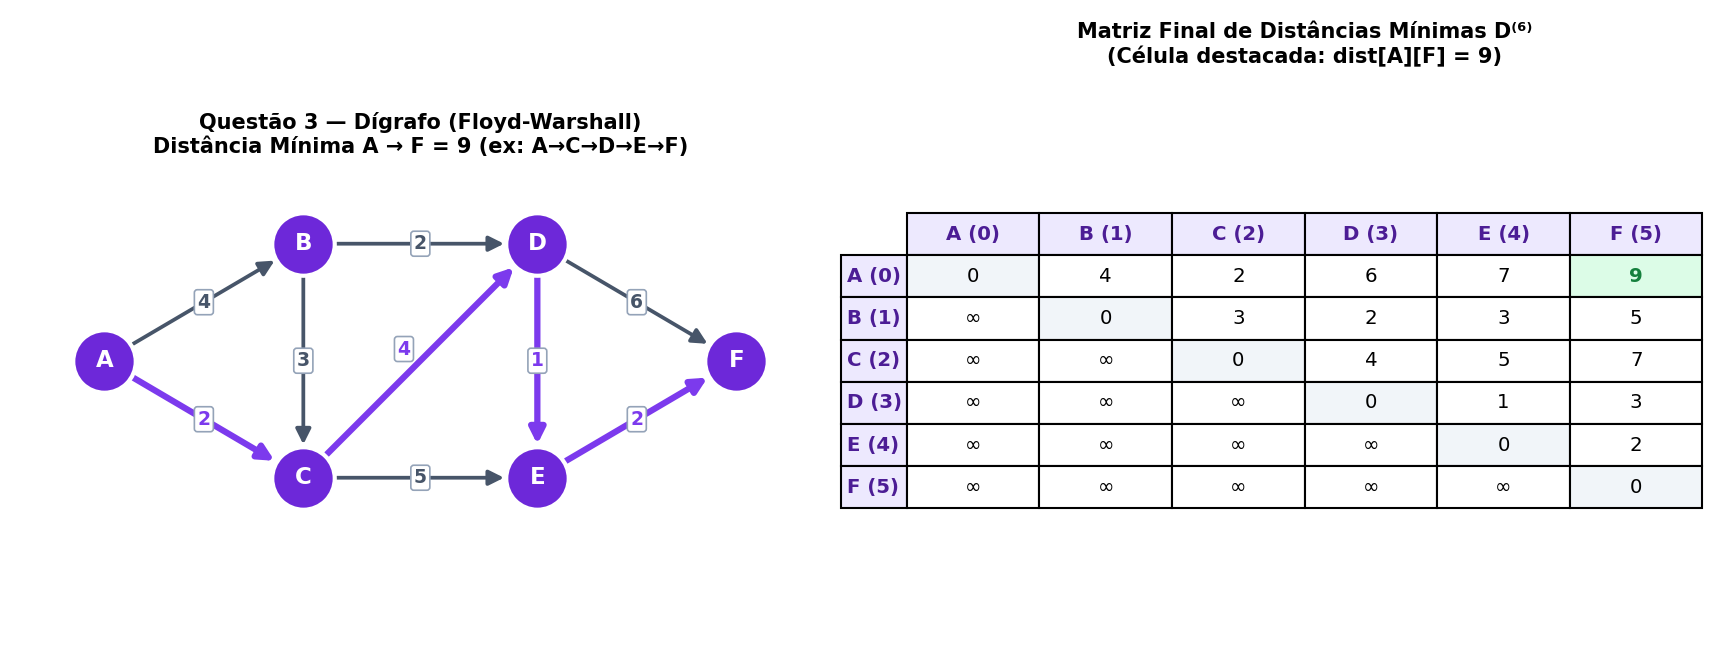

In [5]:
# Questão 3.3 — Implementação Completa do Floyd-Warshall em Python (Google Colab)
INF = float('inf')
V = 6
nomes = ['A', 'B', 'C', 'D', 'E', 'F']

dist = [
    [0,   4,   2,   INF, INF, INF],
    [INF, 0,   3,   2,   INF, INF],
    [INF, INF, 0,   4,   5,   INF],
    [INF, INF, INF, 0,   1,   6  ],
    [INF, INF, INF, INF, 0,   2  ],
    [INF, INF, INF, INF, INF, 0  ]
]

# Matriz de roteamento (sucessores) para reconstruir caminhos
prox = [[j if dist[i][j] != INF and i != j else -1 for j in range(V)] for i in range(V)]

def imprimir_matriz(m, titulo):
    print(f"=== {titulo} ===")
    print("      " + " ".join(f"{n:>4s}" for n in nomes))
    for i in range(V):
        linha = " ".join(" INF" if m[i][j] == INF else f"{m[i][j]:4d}" for j in range(V))
        print(f"  {nomes[i]} | {linha}")
    print()

imprimir_matriz(dist, "Matriz Inicial D^(0)")

for k in range(V):
    for i in range(V):
        for j in range(V):
            if dist[i][k] + dist[k][j] < dist[i][j]:
                dist[i][j] = dist[i][k] + dist[k][j]
                prox[i][j] = prox[i][k]
    imprimir_matriz(dist, f"Após k = {k} (Intermediário {nomes[k]})")

# Reconstruir o caminho mínimo de A (0) até F (5)
u, destino = 0, 5
caminho = [nomes[u]]
while u != destino:
    u = prox[u][destino]
    caminho.append(nomes[u])
print(f"Menor distância de A até F = {dist[0][5]}")
print(f"Caminho recuperado pela matriz de roteamento: {' -> '.join(caminho)}")

In [6]:
# Questão 3.3 — Implementação Completa do Floyd-Warshall em C (Compilada com gcc no Colab)
floyd_c = r'''#include <stdio.h>
#define INF 99999
#define V 6

int main() {
    int dist[V][V] = {
        {0, 4, 2, INF, INF, INF},
        {INF, 0, 3, 2, INF, INF},
        {INF, INF, 0, 4, 5, INF},
        {INF, INF, INF, 0, 1, 6},
        {INF, INF, INF, INF, 0, 2},
        {INF, INF, INF, INF, INF, 0}
    };
    for (int k = 0; k < V; k++)
        for (int i = 0; i < V; i++)
            for (int j = 0; j < V; j++) {
                // Atualizar dist[i][j] se o caminho por k for menor
                if (dist[i][k] + dist[k][j] < dist[i][j]) {
                    dist[i][j] = dist[i][k] + dist[k][j];
                }
            }

    // Imprimir a matriz final de distancias
    printf("Matriz Final de Distancias (Floyd-Warshall):\n");
    for (int i = 0; i < V; i++) {
        for (int j = 0; j < V; j++) {
            if (dist[i][j] == INF)
                printf("%5s", "INF");
            else
                printf("%5d", dist[i][j]);
        }
        printf("\n");
    }
    return 0;
}
'''
with open("floyd_warshall.c", "w") as f:
    f.write(floyd_c)
import subprocess
subprocess.run(["gcc", "floyd_warshall.c", "-o", "floyd_warshall"], check=True)
print(subprocess.run(["./floyd_warshall"], capture_output=True, text=True, check=True).stdout, end="")

Matriz Final de Distancias (Floyd-Warshall):
    0    4    2    6    7    9
  INF    0    3    2    3    5
  INF  INF    0    4    5    7
  INF  INF  INF    0    1    3
  INF  INF  INF  INF    0    2
  INF  INF  INF  INF  INF    0


## Síntese Comparativa: Dijkstra × Bellman-Ford × Floyd-Warshall

| Critério | Dijkstra | Bellman-Ford | Floyd-Warshall |
| :--- | :--- | :--- | :--- |
| **Subproblema Resolvido** | **Um-para-todos** (*Single-Source Shortest Path — SSSP*) | **Um-para-todos** (*Single-Source Shortest Path — SSSP*) | **Todos os pares** (*All-Pairs Shortest Path — APSP*) |
| **Paradigma de Projeto** | Algoritmo **Guloso** (*Greedy*) | **Programação Dinâmica** / Relaxamento global por arestas | **Programação Dinâmica** matricial sobre vértices intermediários $k$ |
| **Ordem de Complexidade** | • Matriz / Vetor: **$O(V^2)$**<br>• Lista + Min-Heap: **$O((V + E) \log V)$** | **$O(V \cdot E)$**<br>*(Em grafos densos $E \approx V^2$, chega a $O(V^3)$)* | **$\Theta(V^3)$** em tempo<br>**$\Theta(V^2)$** em espaço |
| **Pesos Negativos** | **Não suporta** (pode produzir distâncias erradas ao fechar vértices prematuramente) | **Suporta** arestas negativas e **detecta ciclos de peso negativo** | **Suporta** arestas negativas (e detecta ciclos negativos se algum $D_{ii} < 0$) |
| **Vantagens Principais** | Mais rápido para fonte única quando não há pesos negativos (como vimos na Questão 1). | Robusto na presença de pesos negativos (como o arco $E \to D(-3)$ na Questão 2) e fácil de implementar com lista de arestas. | Código extremamente compacto (3 laços `for`) que entrega de uma só vez as distâncias entre **todos** os pares (Questão 3). |
| **Limitações** | Falha com pesos negativos; para todos os pares exige $V$ execuções. | Mais lento que Dijkstra quando todos os pesos são positivos ($O(V \cdot E)$ vs $O((V+E)\log V)$). | Custo fixo $\Theta(V^3)$ mesmo em grafos esparsos e exige memória $O(V^2)$. |